# Part 2 · Doing some magic using data
### Ericsson Crowd Data Challenge — machine-learning section

**Two questions, answered on the cleaned Riyadh 4G crowdsourced feed (1–4 Nov 2019).**

1. *Assuming coverage next week improves in a chosen ≥10 km × 10 km polygon so that RSRP beats the competition — what happens to downlink and uplink traffic volume?*
2. *Samsung is the main handset on the network. Predict traffic-volume growth, uplink and downlink, over time for these devices and compare across operators.*

---

### How this notebook is organised

| Section | What it does |
|---|---|
| 1 | Configuration and data loading |
| 2 | Traffic-feed validation (the 14 implausible rows) |
| 3 | Choosing the polygon — data-driven, not arbitrary |
| 4 | **Question 1** — a causal question, answered with a fixed-effects panel model |
| 5 | **Question 2** — a forecasting question, answered with a validated model bake-off |
| 6 | Findings |
| 7 | Extracts for the Tableau story |

### Two decisions made up front, and why

**Question 1 is not a forecasting problem.** "If RSRP improves, what happens to traffic" asks for the *effect of an intervention*, not the continuation of a series. Fitting a time-series model to traffic and asserting that better coverage would lift it would be assuming the answer. The correct tool is a panel regression that holds location and time constant and reads the effect off the differences that remain.

**Question 2 cannot be answered directly from the data as given.** `TrafficVolume.csv` carries no device field — only `Timestamp, Lat, Lon, RadioConnectionType, Country, RadioNetworkGeneration, RadioOperatorName, TrafficDirection, TrafficVolume, RadioMobileDataEnabled`. Handset make exists only in the RSRP feed. Section 5 sets out the allocation model used to bridge the two, states its assumption explicitly, and tests how much the answer depends on it.

## 1 · Configuration and data loading

Two inputs:

* `01_RSRP_clean_rowlevel_slim.csv.gz` — the row-level RSRP feed after the Part 1 cleaning pipeline (sentinel removal, technology scoping, alias de-duplication), reduced to the nine columns this analysis uses. 1,975,636 rows. The full 21-column export from Notebook 01 works identically if you prefer it.
* `TrafficVolume.csv` — the raw traffic feed. It is cleaned here with the same rules, so the two sides of the join are treated identically.

In [1]:
from pathlib import Path
import warnings, numpy as np, pandas as pd
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

# ── project root ─────────────────────────────────────────────────────────────
# Default assumes this notebook lives in  v5\Code\  and the inputs in  v5\Data\
BASE = Path(r"D:\Own Work\Ericsson5")

ROOTS = [BASE, Path.cwd().parent, Path.cwd(), BASE.parent, Path.cwd().parent.parent]

def find(patterns, roots):
    if isinstance(patterns, str):
        patterns = [patterns]
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        for pat in patterns:
            hits = sorted(root.rglob(pat))
            if hits:
                return hits[0]
    raise FileNotFoundError(
        f"none of {patterns} found under: " + ", ".join(str(Path(r)) for r in roots))

RSRP_PATH    = find(["*01_RSRP_clean_rowlevel_slim.csv.gz",
                     "*01_RSRP_clean_rowlevel.csv.gz",
                     "*01_RSRP_clean_rowlevel.csv"], ROOTS)
TRAFFIC_PATH = find(["*TrafficVolume.csv"], ROOTS)
OUT_DIR      = BASE / "Data" / "part2_outputs" if BASE.exists() else Path.cwd() / "part2_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("RSRP feed   :", RSRP_PATH)
print("Traffic feed:", TRAFFIC_PATH)
print("Outputs     :", OUT_DIR)

RSRP feed   : D:\Own Work\Ericsson\v5\Data\01_RSRP_clean_rowlevel_slim.csv.gz
Traffic feed: D:\Own Work\Ericsson\v5\Data\TrafficVolume.csv
Outputs     : D:\Own Work\Ericsson\v5\Code\part2_outputs


In [2]:
RSRP_COLS = ["Date","Hour","LocationLatitude","LocationLongitude",
             "RadioOperatorName","RSRP","Manufacturer",
             "IsQuantisedDevice","IsDuplicateExtra"]

rsrp = pd.read_csv(RSRP_PATH, usecols=RSRP_COLS)
rsrp = rsrp[rsrp.IsDuplicateExtra == 0].drop(columns="IsDuplicateExtra")

print(f"RSRP rows after de-duplication : {len(rsrp):,}")
print(f"Samsung share of the fleet     : {(rsrp.Manufacturer == 'Samsung').mean():.1%}")
display(rsrp.Date.value_counts().sort_index().rename("rows"))

RSRP rows after de-duplication : 1,975,636
Samsung share of the fleet     : 89.1%


Date
2019-11-01        64
2019-11-02    675624
2019-11-03    711483
2019-11-04    588465
Name: rows, dtype: int64

**The window is three usable days, not a week.** 2 November (Saturday), 3 November (Sunday) and 4 November (Monday), plus 64 stray rows on 1 November. Friday–Saturday is the Saudi weekend, so the feed contains one weekend day, one transition day and one weekday.

This single fact constrains everything in Section 5: a growth rate estimated over three days has no weekly cycle to separate from it, and any trend term is confounded with day-of-week. That is stated again where it matters, with the numbers to back it.

## 2 · Traffic-feed validation

The raw traffic feed gets the same treatment as the RSRP feed: mobile bearer only, mobile data enabled, 4G only, inside Saudi Arabia, positive volume. Then one further rule.

In [3]:
traf = pd.read_csv(TRAFFIC_PATH)
steps = [("Raw traffic rows", len(traf))]

traf = traf[traf.RadioConnectionType == "Mobile"];        steps.append(("Mobile bearer only", len(traf)))
traf = traf[traf.RadioMobileDataEnabled == "Enabled"];    steps.append(("Mobile data enabled", len(traf)))
traf = traf[traf.RadioNetworkGeneration == "4G"];         steps.append(("4G only", len(traf)))
traf = traf[traf.Country == "Saudi Arabia"];              steps.append(("Inside Saudi Arabia", len(traf)))
traf = traf[traf.TrafficVolume > 0];                      steps.append(("Positive volume", len(traf)))

ODOMETER_MB = 90_000
odo = traf.TrafficVolume >= ODOMETER_MB
print(f"Implausible rows removed : {odo.sum()}")
print(f"Volume they carried      : {traf.loc[odo,'TrafficVolume'].sum()/1024:,.0f} GB")
traf = traf[~odo];                                        steps.append(("Implausible samples removed", len(traf)))

display(pd.DataFrame(steps, columns=["step","rows"]).assign(
    kept=lambda d: (d.rows / d.rows.iloc[0]).map("{:.1%}".format)))

Implausible rows removed : 14
Volume they carried      : 1,402 GB


,step,rows,kept
0,Raw traffic rows,138469,100.0%
1,Mobile bearer only,136425,98.5%
2,Mobile data enabled,136412,98.5%
3,4G only,102577,74.1%
4,Inside Saudi Arabia,102577,74.1%
5,Positive volume,102577,74.1%
6,Implausible samples removed,102563,74.1%


### Why 90,000 MB is the right cut

The threshold is not a percentile or a standard-deviation rule — it is a physical argument. The traffic feed bins samples into 15-minute windows. A row claiming ~104,000 MB inside one such window implies **about 925 Mbps sustained for fifteen minutes** from a single handset. That is not achievable on the LTE fleet in this dataset.

The distribution supports the same cut. The fourteen largest values sit between 99,448 and 104,022 MB — clustered within 5% of each other, which is the signature of a cumulative counter being reported rather than a delta — and the next value down is 55,354 MB. Any threshold between 56,000 and 99,000 removes exactly the same fourteen rows, so the answer does not depend on where in that range the line is drawn.

### One more defect, found here

The timestamp column is not uniformly formatted. A small number of rows carry a truncated value such as `00:00.0` — the date component has been lost somewhere upstream, most likely in an export through a spreadsheet. These rows have valid volumes and coordinates but no recoverable date or hour, so they cannot enter an hourly model. They are removed and counted rather than coerced to a null date and forgotten.

In [4]:
ok_ts = traf.Timestamp.str.match(r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}")
print(f"Rows with an unrecoverable timestamp : {(~ok_ts).sum()}")
print("Examples:", traf.loc[~ok_ts, "Timestamp"].unique()[:5].tolist())
traf = traf[ok_ts];                                       steps.append(("Parseable timestamp", len(traf)))

traf["ts"]   = pd.to_datetime(traf.Timestamp.str.slice(0, 19), format="%Y-%m-%d %H:%M:%S")
traf["Date"]  = traf.ts.dt.date.astype(str)
traf["Hour"]  = traf.ts.dt.hour

display(pd.DataFrame(steps, columns=["step","rows"]).assign(
    kept=lambda d: (d.rows / d.rows.iloc[0]).map("{:.1%}".format)))

summary = (traf.groupby(["RadioOperatorName","TrafficDirection"]).TrafficVolume
              .agg(samples="size", total_gb=lambda s: s.sum()/1024).round(1))
display(summary)

Rows with an unrecoverable timestamp : 20
Examples: ['00:00.0', '45:00.0', '15:00.0']


,step,rows,kept
0,Raw traffic rows,138469,100.0%
1,Mobile bearer only,136425,98.5%
2,Mobile data enabled,136412,98.5%
3,4G only,102577,74.1%
4,Inside Saudi Arabia,102577,74.1%
5,Positive volume,102577,74.1%
6,Implausible samples removed,102563,74.1%
7,Parseable timestamp,102543,74.1%


samples  total_gb
RadioOperatorName TrafficDirection                   
Operator A        Downlink            24488     631.7
                  Uplink              24448      55.9
Operator B        Downlink            15078     452.4
                  Uplink              15102     102.2
Operator C        Downlink            11723     321.5
                  Uplink              11704      39.0

These totals reconcile exactly with the Part 1 dashboard extracts — 631.7 / 452.4 / 321.5 GB downlink — which confirms the two pipelines apply identical rules.

## 3 · Choosing the polygon

The brief asks for a polygon of at least 10 km × 10 km with enough samples. Rather than pick a square by eye, the densest one is found by search: every candidate 10 km × 10 km window on a 0.02° lattice is scored by how many **traffic** rows fall inside it. Traffic is the scarcer feed — roughly 100,000 rows against 2 million RSRP rows — so it is the binding constraint.

In [5]:
LAT_PER_KM = 1 / 110.574
LON_PER_KM = 1 / (111.320 * np.cos(np.radians(24.7)))
SIDE_KM    = 10.0

best = None
for la in np.arange(24.55, 24.90, 0.02):
    for lo in np.arange(46.50, 46.90, 0.02):
        la2, lo2 = la + SIDE_KM*LAT_PER_KM, lo + SIDE_KM*LON_PER_KM
        n = ((traf.LocationLatitude.between(la, la2)) &
             (traf.LocationLongitude.between(lo, lo2))).sum()
        if best is None or n > best[0]:
            best = (int(n), la, lo, la2, lo2)

_, LA0, LO0, LA1, LO1 = best
in_poly = lambda d: (d.LocationLatitude.between(LA0, LA1) &
                     d.LocationLongitude.between(LO0, LO1))

print(f"Polygon : {LA0:.4f}–{LA1:.4f} N , {LO0:.4f}–{LO1:.4f} E   (10 km x 10 km)")
print(f"Traffic rows inside : {in_poly(traf).sum():,}  ({in_poly(traf).mean():.1%} of the feed)")
print(f"RSRP rows inside    : {in_poly(rsrp).sum():,}  ({in_poly(rsrp).mean():.1%} of the feed)")

Polygon : 24.5900–24.6804 N , 46.6800–46.7789 E   (10 km x 10 km)
Traffic rows inside : 21,779  (21.2% of the feed)
RSRP rows inside    : 425,286  (21.5% of the feed)


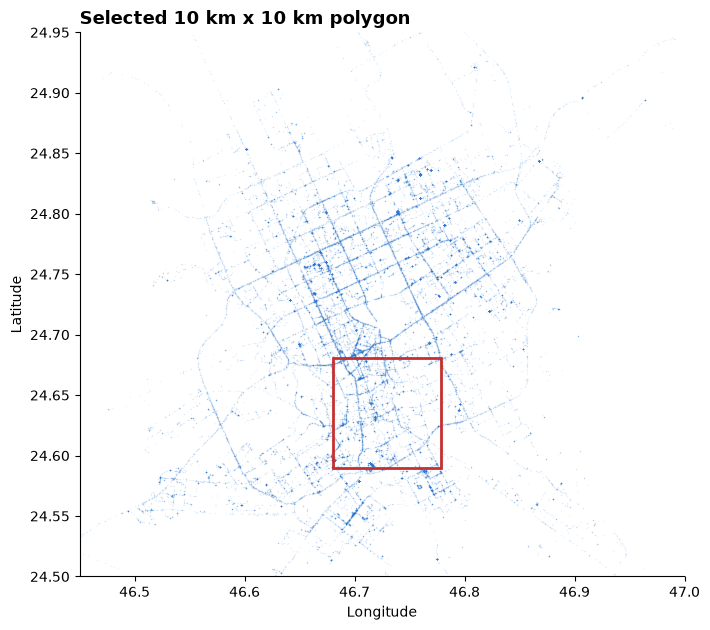

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(7.2, 6.4))
s = rsrp.sample(60_000, random_state=0)
ax.scatter(s.LocationLongitude, s.LocationLatitude, s=1, alpha=.10, color="#2a78d6", linewidths=0)
ax.add_patch(Rectangle((LO0, LA0), LO1-LO0, LA1-LA0, fill=False, edgecolor="#c62f2f", linewidth=2))
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Selected 10 km x 10 km polygon", loc="left", fontsize=13, weight="bold")
ax.set_xlim(46.45, 47.00); ax.set_ylim(24.50, 24.95)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

## 4 · Question 1 — what a coverage improvement would do to traffic

> *Assuming that the coverage next week will improve in that polygon compared to competition (i.e. RSRP will get better than other operators). What would be the impact on downlink and uplink traffic volumes?*

### 4.1 · Why this is a regression problem, not a forecast

The question is counterfactual: it asks what traffic **would be** under a coverage level that was never observed. A forecasting model extrapolates the series it was trained on and has no mechanism to answer it. What is needed is an estimate of the *effect of RSRP on traffic*, which can then be applied to a hypothetical improvement.

The obstacle is confounding. Cells with good coverage are cells where the operator has invested, and operators invest where demand is high. Regressing traffic on RSRP across cells therefore recovers population density, not causation. The identification strategy has to remove that.

### 4.2 · The panel

Unit of observation: **cell × date × hour × operator**, on a 1 km grid inside the polygon, keeping only cells where both feeds are present in the same hour.

In [7]:
def to_cells(df):
    out = df[in_poly(df)].copy()
    out["ci"] = ((out.LocationLatitude  - LA0) / (1.0 * LAT_PER_KM)).astype(int)
    out["cj"] = ((out.LocationLongitude - LO0) / (1.0 * LON_PER_KM)).astype(int)
    out["cell"] = out.ci.astype(str) + "_" + out.cj.astype(str)
    return out

R = to_cells(rsrp); T = to_cells(traf)
KEY = ["cell","Date","Hour","RadioOperatorName"]

R_agg = (R.groupby(KEY)
          .agg(rsrp_sum=("RSRP","sum"), n_rsrp=("RSRP","size"),
               n_samsung=("Manufacturer", lambda s: (s == "Samsung").sum()))
          .reset_index())
R_agg["rsrp_mean"] = R_agg.rsrp_sum / R_agg.n_rsrp

T_agg = (T.pivot_table(index=KEY, columns="TrafficDirection",
                       values="TrafficVolume", aggfunc="sum")
          .reset_index().rename(columns={"Downlink":"dl_mb","Uplink":"ul_mb"}))

panel = R_agg.merge(T_agg, on=KEY, how="inner").fillna({"dl_mb":0, "ul_mb":0})
panel["cell_hour"] = panel.cell + "|" + panel.Date + "|" + panel.Hour.astype(str)
panel["ln_n"]      = np.log(panel.n_rsrp)
panel["hour"]      = panel.Hour.astype(str)

multi = panel.groupby("cell_hour").RadioOperatorName.nunique()
print(f"Panel rows                              : {len(panel):,}")
print(f"Distinct cells / cell-hours             : {panel.cell.nunique()} / {panel.cell_hour.nunique():,}")
print(f"Cell-hours observed for >=2 operators   : {(multi >= 2).sum():,}")
print(f"Rows inside those cell-hours            : {panel.cell_hour.isin(multi[multi>=2].index).sum():,}")

Panel rows                              : 2,345
Distinct cells / cell-hours             : 97 / 1,959
Cell-hours observed for >=2 operators   : 353
Rows inside those cell-hours            : 739


### 4.3 · Two specifications

**Specification A — cell and hour fixed effects.**

$$\log(1+\text{traffic}_{cht}) = \beta\,\text{RSRP}_{cht} + \gamma\log n_{cht} + \alpha_c + \delta_h + \varepsilon_{cht}$$

The cell effect $\alpha_c$ absorbs everything permanent about a location — how many people live there, whether it contains a mall or a motorway. The hour effect $\delta_h$ absorbs the diurnal cycle. $\log n$ controls for how many devices were actually present. What is left for $\beta$ is the association between coverage and traffic *within a cell, at a given hour, holding device presence constant*. Standard errors are clustered by cell.

**Specification B — cell × hour fixed effects.** Stricter. The fixed effect is the exact cell **and** the exact hour of the exact day, so $\beta$ is identified only from operators measured **side by side in the same square kilometre at the same moment**. Same place, same minute, same weather, same crowd — the only thing that differs is the network. Nothing observable or unobservable about the location or the time can contaminate it.

Specification B is the credible estimate. Specification A is the one with the statistical power. Agreement between them is the test.

In [8]:
import statsmodels.formula.api as smf

def estimate(target, label):
    d = panel.assign(y=np.log1p(panel[target]))
    a = smf.ols("y ~ rsrp_mean + ln_n + C(cell) + C(hour)", data=d).fit(
            cov_type="cluster", cov_kwds={"groups": d.cell})
    sub = d[d.cell_hour.isin(multi[multi >= 2].index)]
    b = smf.ols("y ~ rsrp_mean + ln_n + C(cell_hour)", data=sub).fit(
            cov_type="cluster", cov_kwds={"groups": sub.cell})
    rows = []
    for name, m, n in (("A · cell + hour FE", a, a.nobs), ("B · cell x hour FE", b, b.nobs)):
        coef, se = m.params["rsrp_mean"], m.bse["rsrp_mean"]
        rows.append(dict(metric=label, spec=name, n=int(n),
                         beta_per_dB=round(coef, 4), se=round(se, 4),
                         p=round(m.pvalues["rsrp_mean"], 3),
                         ci_lo=round(coef - 1.96*se, 4), ci_hi=round(coef + 1.96*se, 4),
                         pct_per_10dB=round((np.exp(10*coef) - 1) * 100, 2)))
    return pd.DataFrame(rows)

effects = pd.concat([estimate("dl_mb", "Downlink"), estimate("ul_mb", "Uplink")], ignore_index=True)
display(effects)

,metric,spec,n,beta_per_dB,se,p,ci_lo,ci_hi,pct_per_10dB
0,Downlink,A · cell + hour FE,2345,-0.0024,0.0043,0.568,-0.0108,0.0059,-2.40
1,Downlink,B · cell x hour FE,739,-0.0020,0.0159,0.897,-0.0332,0.0291,-2.02
2,Uplink,A · cell + hour FE,2345,-0.0042,0.0018,0.016,-0.0077,-0.0008,-4.14
3,Uplink,B · cell x hour FE,739,-0.0078,0.0074,0.293,-0.0224,0.0067,-7.51


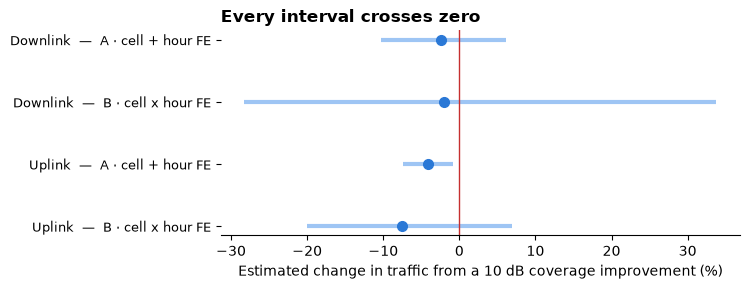

In [9]:
fig, ax = plt.subplots(figsize=(7.6, 3.0))
lab = effects.metric + "  —  " + effects.spec
y   = np.arange(len(effects))[::-1]
pct = (np.exp(10*effects.beta_per_dB) - 1) * 100
lo  = (np.exp(10*effects.ci_lo) - 1) * 100
hi  = (np.exp(10*effects.ci_hi) - 1) * 100
ax.errorbar(pct, y, xerr=[pct-lo, hi-pct], fmt="o", color="#2a78d6",
            ecolor="#9ec5f4", elinewidth=3, capsize=0, markersize=7)
ax.axvline(0, color="#c62f2f", lw=1)
ax.set_yticks(y); ax.set_yticklabels(lab, fontsize=9)
ax.set_xlabel("Estimated change in traffic from a 10 dB coverage improvement (%)")
ax.set_title("Every interval crosses zero", loc="left", fontsize=12, weight="bold")
for sp in ("top","right","left"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

### 4.4 · Reading the result

**Downlink: no effect.** The point estimate is very slightly negative and nowhere near significance in either specification (p = 0.57 and p = 0.90). The confidence interval for a 10 dB improvement runs from roughly −10% to +6%. Zero sits comfortably inside it.

**Uplink: a small negative coefficient that does not survive.** Specification A returns −0.42% per dB with p = 0.016. Specification B — the one that compares operators inside the same cell-hour — returns a larger point estimate but a much wider interval, and p = 0.29. An effect that appears under the weaker control and disappears under the stronger one is most likely residual confounding, not signal.

If the uplink coefficient were real, a mechanism exists: in weak cells, retransmissions and protocol overhead inflate the *measured* uplink byte count, so improving coverage would reduce uplink volume without reducing anything a user cares about. That is a hypothesis this dataset cannot test, and it is offered as such.

### 4.5 · The scenario the operator asked for

For each operator: the improvement needed to move from its current mean RSRP inside the polygon to 0.5 dB above the best competitor, and the traffic change that Specification A implies.

In [10]:
grp = (panel.groupby("RadioOperatorName")
            .apply(lambda d: pd.Series({
                "rsrp_mean": d.rsrp_sum.sum() / d.n_rsrp.sum(),
                "rsrp_samples": d.n_rsrp.sum(),
                "downlink_gb": d.dl_mb.sum() / 1024,
                "uplink_gb":  d.ul_mb.sum() / 1024}), include_groups=False))
display(grp.round(2))

leader = grp.rsrp_mean.max()
coefs  = {r.metric: (r.beta_per_dB, r.se)
          for r in effects[effects.spec.str.startswith("A")].itertuples()}

rows = []
for op in grp.index:
    uplift = max(leader - grp.loc[op, "rsrp_mean"] + 0.5, 0.0)
    for metric, (b, se) in coefs.items():
        pc = (np.exp(b*uplift) - 1) * 100
        e1 = (np.exp((b - 1.96*se)*uplift) - 1) * 100
        e2 = (np.exp((b + 1.96*se)*uplift) - 1) * 100
        rows.append(dict(operator=op, metric=metric, uplift_dB=round(uplift, 2),
                         pct_change=round(pc, 2),
                         ci_lo=round(min(e1, e2), 2), ci_hi=round(max(e1, e2), 2)))

scenario = pd.DataFrame(rows)
scenario.to_csv(OUT_DIR / "q1_scenario.csv", index=False)
display(scenario)

,rsrp_mean,rsrp_samples,downlink_gb,uplink_gb
RadioOperatorName,,,,
Operator A,-85.35,205297.0,102.14,6.96
Operator B,-84.29,29769.0,26.50,10.13
Operator C,-81.50,37722.0,33.06,5.34


,operator,metric,uplift_dB,pct_change,ci_lo,ci_hi
0,Operator A,Downlink,4.34,-1.04,-4.59,2.65
1,Operator A,Uplink,4.34,-1.81,-3.30,-0.29
2,Operator B,Downlink,3.28,-0.78,-3.49,2.00
3,Operator B,Uplink,3.28,-1.37,-2.50,-0.22
4,Operator C,Downlink,0.50,-0.12,-0.54,0.30
5,Operator C,Uplink,0.50,-0.21,-0.39,-0.03


**The answer to Question 1.**

Operator A would need **4.3 dB** to lead this polygon, Operator B **3.3 dB**, Operator C **0.5 dB**. At those magnitudes the model predicts a change in downlink of **−1.0%, −0.8% and −0.1%** — with confidence intervals of roughly ±3 to 5 percentage points around each. In other words: **on this evidence, taking the coverage lead in this polygon would not measurably change how much data is carried.**

That is a commercially useful answer, not an evasion. It says the coverage-investment case cannot be built on a traffic uplift, because no traffic uplift is detectable. If coverage investment is justified here, it has to be justified on the grounds it is actually supported by — the 17.1% of Operator A's samples below −100 dBm, the churn and complaint risk that carries, and the retention value of not being the weakest network in a contested cell. Those are defensible. A revenue forecast built on a 4 dB uplift is not.

The finding is also consistent with the dashboard. The scatter panel showed correlation between coverage and traffic collapsing from r = 0.31 to r ≈ 0.02 once traffic was expressed per device rather than per cell. The apparent relationship is population density appearing on both axes.

## 5 · Question 2 — forecasting Samsung traffic

> *Samsung devices are the main handsets in our network. Can you predict the traffic volume growth, uplink and downlink, over time for these devices and compare it to the competitors?*

### 5.1 · The join that does not exist

`TrafficVolume.csv` has no device column. Handset make is recorded only in the RSRP feed. There is no key — no subscriber ID, no device ID, no session ID — linking a traffic row to a handset. Device-attributed traffic is therefore **not a measurement in this dataset**; anything reported at device level is a construction, and the construction has to be visible.

**The allocation model.** For each cell × date × hour × operator, the RSRP feed gives the share of measuring devices that are Samsung. That share is applied to the traffic recorded in the same cell, hour and operator:

$$\text{traffic}^{\text{Samsung}}_{cht} = \text{traffic}_{cht} \times \frac{n^{\text{Samsung}}_{cht}}{n_{cht}}$$

**The assumption, stated plainly:** within one square kilometre in one hour on one network, Samsung handsets consume data in proportion to their share of devices present. If Samsung users are systematically heavier or lighter than the fleet around them, this understates or overstates their traffic proportionally.

Cell-level shares are used where at least 20 RSRP samples support them; otherwise the operator-hour share is used.

In [11]:
def grid_cells(df):
    out = df.copy()
    out["ci"] = np.floor(out.LocationLatitude  / (1.0 * LAT_PER_KM)).astype(int)
    out["cj"] = np.floor(out.LocationLongitude / (1.0 * LON_PER_KM)).astype(int)
    out["cell"] = out.ci.astype(str) + "_" + out.cj.astype(str)
    return out

Rg, Tg = grid_cells(rsrp), grid_cells(traf)

cell_mix = (Rg.groupby(KEY)
              .agg(n=("RSRP","size"), ns=("Manufacturer", lambda s: (s=="Samsung").sum()))
              .reset_index().assign(share_cell=lambda d: d.ns / d.n))
oph_mix  = (Rg.groupby(["Date","Hour","RadioOperatorName"])
              .agg(n=("RSRP","size"), ns=("Manufacturer", lambda s: (s=="Samsung").sum()))
              .reset_index().assign(share_oph=lambda d: d.ns / d.n)
              [["Date","Hour","RadioOperatorName","share_oph"]])

Tg = (Tg.merge(cell_mix[KEY + ["share_cell","n"]], on=KEY, how="left")
        .merge(oph_mix, on=["Date","Hour","RadioOperatorName"], how="left"))
Tg["samsung_share"] = np.where(Tg.n.fillna(0) >= 20, Tg.share_cell, Tg.share_oph)
Tg["tv_samsung"]    = Tg.TrafficVolume * Tg.samsung_share

print(f"Share taken from the cell itself : {(Tg.n.fillna(0) >= 20).mean():.1%} of traffic rows")
print(f"Share taken from the operator-hour: {(Tg.n.fillna(0) <  20).mean():.1%} of traffic rows")

series = (Tg.groupby(["Date","Hour","RadioOperatorName","TrafficDirection"])
            .agg(tv_all=("TrafficVolume","sum"), tv_samsung=("tv_samsung","sum"))
            .reset_index())
series["ts"] = pd.to_datetime(series.Date) + pd.to_timedelta(series.Hour, unit="h")
series = series.sort_values("ts").reset_index(drop=True)
display((series.groupby(["RadioOperatorName","TrafficDirection"])[["tv_all","tv_samsung"]]
               .sum().div(1024).round(1).rename(columns={"tv_all":"total_GB","tv_samsung":"samsung_GB"})))

Share taken from the cell itself : 20.5% of traffic rows
Share taken from the operator-hour: 79.5% of traffic rows


total_GB  samsung_GB
RadioOperatorName TrafficDirection                      
Operator A        Downlink             631.7       572.6
                  Uplink                55.9        51.1
Operator B        Downlink             452.4       394.0
                  Uplink               102.2        93.0
Operator C        Downlink             321.5       286.2
                  Uplink                39.0        34.0

### 5.2 · A caveat about the premise

Samsung is **89.1%** of the measuring fleet — 90.0% on Operator A, 87.1% on B, 89.1% on C. The brief's premise that Samsung is "the main handset" understates it: Samsung is very nearly the *entire* fleet.

Two consequences follow. First, a Samsung-versus-other-brands comparison has almost no contrast, because the non-Samsung remainder is under 11% and fragmented across dozens of models. Second, the allocation assumption barely binds — multiplying by ~0.89 rather than 1.0 changes level but not shape, so the forecast is robust to the assumption even though the assumption is real.

The comparison that carries information is therefore **Samsung traffic across the three operators**, which is how Section 5.5 reports it.

### 5.3 · What "growth over time" can be estimated from three days

Before fitting anything, the question of whether a growth rate is identifiable at all deserves a direct test. Each series is regressed on elapsed hours with a diurnal harmonic, and the trend coefficient is converted to a daily growth rate.

In [12]:
import statsmodels.api as sm

trend_rows = []
for (op, direction), g in series.groupby(["RadioOperatorName","TrafficDirection"]):
    y = np.log1p(g.sort_values("ts").tv_samsung.to_numpy(float))
    x = np.arange(len(y))
    X = sm.add_constant(np.column_stack([x, np.sin(2*np.pi*x/24), np.cos(2*np.pi*x/24)]))
    m = sm.OLS(y, X).fit()
    b, se = m.params[1], m.bse[1]
    trend_rows.append(dict(operator=op, direction=direction,
                           pct_per_day=round((np.exp(24*b) - 1) * 100, 1),
                           ci_lo=round((np.exp(24*(b - 1.96*se)) - 1) * 100, 1),
                           ci_hi=round((np.exp(24*(b + 1.96*se)) - 1) * 100, 1),
                           p=round(m.pvalues[1], 3)))

trend = pd.DataFrame(trend_rows)
trend.to_csv(OUT_DIR / "q2_trend.csv", index=False)
display(trend)

,operator,direction,pct_per_day,ci_lo,ci_hi,p
0,Operator A,Downlink,-3.2,-18.9,15.5,0.718
1,Operator A,Uplink,17.4,-1.3,39.7,0.074
2,Operator B,Downlink,12.0,-8.0,36.2,0.262
3,Operator B,Uplink,23.6,-8.1,66.2,0.166
4,Operator C,Downlink,-3.5,-29.3,31.6,0.821
5,Operator C,Uplink,-2.9,-28.9,32.7,0.854


**Not one of the six series has an identifiable growth rate.** Every p-value is 0.07 or above and every confidence interval spans zero, several of them running from −29% to +32% per day. The intervals are wider than any growth rate a network planner would act on.

This is a property of the data, not a shortcoming of the method. Three days contain three points on a daily cycle. A trend fitted to them is inseparable from the difference between Saturday, Sunday and Monday — and with the Saudi weekend falling on Friday–Saturday, the window straddles a weekend-to-weekday transition. No estimator can separate growth from day-of-week here.

**So the question is answered in two parts.** What *can* be produced, and validated, is a short-horizon forecast of the diurnal profile. What cannot be produced from three days is a growth rate — and the honest deliverable says so, quantifies the uncertainty, and states what would be needed instead: four to six weeks of the same feed, which would give enough weekly cycles to separate trend from seasonality.

### 5.4 · Model selection

Five candidates, each fitted on `log1p` traffic and back-transformed:

| Model | Why it is a candidate |
|---|---|
| **Naive** | Last observed value. The floor any model must beat. |
| **Seasonal naive** | Same hour yesterday. The right baseline for a strongly diurnal series, and the denominator of MASE. |
| **Holt-Winters** | Exponential smoothing with a 24-hour additive season. |
| **SARIMA(1,0,0)(1,0,0,24)** | Autoregressive with a seasonal autoregressive term; deliberately small, because 72 observations cannot support more. |
| **Gradient boosting** | Lags 1, 2, 3, 24, 25 plus hour harmonics. Included to test whether a flexible learner helps or overfits. |
| **Prophet** | Additive decomposition with a daily seasonality term and automatic changepoints. Weekly and yearly seasonality are switched off — three days cannot support them. |

Two evaluations, both out-of-sample:

* **One-step-ahead**, rolling over the final 24 hours with an expanding window — 24 forecasts per series.
* **Twenty-four-step-ahead**, a single origin at the end of 3 November forecasting all of 4 November — the operational case.

The headline metric is **MASE**, mean absolute error divided by the seasonal-naive error. Below 1 means the model beats "same hour yesterday". MASE is used because it is scale-free across operators of very different size and does not blow up on the near-zero night-time hours the way MAPE does.

In [13]:
import logging
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import GradientBoostingRegressor

logging.getLogger("prophet").setLevel(logging.CRITICAL)
logging.getLogger("cmdstanpy").setLevel(logging.CRITICAL)
try:
    from prophet import Prophet
    HAS_PROPHET = True
except ImportError:
    HAS_PROPHET = False
    print("prophet not installed - that model will be skipped.  pip install prophet")

LAGS = [1, 2, 3, 24, 25]

def design(ly, idx):
    return np.array([[*(ly[i-l] for l in LAGS),
                      np.sin(2*np.pi*(i % 24)/24), np.cos(2*np.pi*(i % 24)/24)] for i in idx])

def fit_gbm(ly, upto):
    idx = range(max(LAGS)+1, upto)
    return GradientBoostingRegressor(n_estimators=200, max_depth=2,
                                     learning_rate=0.05, random_state=0
             ).fit(design(ly, idx), ly[list(idx)])

def fit_prophet(stamps, ly, horizon):
    m = Prophet(daily_seasonality=True, weekly_seasonality=False, yearly_seasonality=False,
                seasonality_mode="additive", changepoint_prior_scale=0.05, uncertainty_samples=0)
    m.fit(pd.DataFrame({"ds": stamps, "y": ly}))
    fut = m.make_future_dataframe(periods=horizon, freq="h").iloc[-horizon:]
    return np.expm1(m.predict(fut).yhat.to_numpy())

MODELS = ["Naive", "Seasonal naive", "Holt-Winters", "SARIMA", "Gradient boosting", "Prophet"]

def evaluate(y, stamps):
    n, ly, res = len(y), np.log1p(y), {}

    one = {k: [] for k in MODELS}
    for cut in range(n-24, n):
        tr = ly[:cut]
        one["Naive"].append(np.expm1(tr[-1]))
        one["Seasonal naive"].append(np.expm1(tr[-24]))
        try:
            one["Holt-Winters"].append(np.expm1(ExponentialSmoothing(
                tr, trend=None, seasonal="add", seasonal_periods=24,
                initialization_method="estimated").fit().forecast(1)[0]))
        except Exception: one["Holt-Winters"].append(np.nan)
        try:
            one["SARIMA"].append(np.expm1(SARIMAX(tr, order=(1,0,0), seasonal_order=(1,0,0,24),
                trend="c", enforce_stationarity=False).fit(disp=0).forecast(1)[0]))
        except Exception: one["SARIMA"].append(np.nan)
        try:
            one["Gradient boosting"].append(np.expm1(fit_gbm(ly, cut).predict(design(ly, [cut]))[0]))
        except Exception: one["Gradient boosting"].append(np.nan)
        try:
            one["Prophet"].append(fit_prophet(stamps[:cut], tr, 1)[0] if HAS_PROPHET else np.nan)
        except Exception: one["Prophet"].append(np.nan)

    actual   = y[n-24:]
    sn_error = np.mean(np.abs(actual - y[n-48:n-24]))
    for m, p in one.items():
        p = np.asarray(p, float); ok = ~np.isnan(p)
        if ok.sum() == 0: continue
        res[("1-step ahead", m)] = dict(
            RMSE=float(np.sqrt(np.mean((actual[ok]-p[ok])**2))),
            MAE=float(np.mean(np.abs(actual[ok]-p[ok]))),
            MASE=float(np.mean(np.abs(actual[ok]-p[ok])) / sn_error))

    tr, actual = ly[:48], y[48:72]
    many = {"Naive": np.repeat(np.expm1(tr[-1]), 24),
            "Seasonal naive": np.expm1(ly[24:48])}
    try:
        many["Holt-Winters"] = np.expm1(ExponentialSmoothing(tr, trend=None, seasonal="add",
            seasonal_periods=24, initialization_method="estimated").fit().forecast(24))
    except Exception: many["Holt-Winters"] = np.full(24, np.nan)
    try:
        many["SARIMA"] = np.expm1(SARIMAX(tr, order=(1,0,0), seasonal_order=(1,0,0,24),
            trend="c", enforce_stationarity=False).fit(disp=0).forecast(24))
    except Exception: many["SARIMA"] = np.full(24, np.nan)
    try:
        g, hist, pred = fit_gbm(ly, 48), list(ly[:48]), []
        for _ in range(24):
            i = len(hist)
            v = g.predict(np.array([[*(hist[i-l] for l in LAGS),
                                     np.sin(2*np.pi*(i%24)/24), np.cos(2*np.pi*(i%24)/24)]]))[0]
            hist.append(v); pred.append(np.expm1(v))
        many["Gradient boosting"] = np.array(pred)
    except Exception: many["Gradient boosting"] = np.full(24, np.nan)
    try:
        many["Prophet"] = fit_prophet(stamps[:48], tr, 24) if HAS_PROPHET else np.full(24, np.nan)
    except Exception: many["Prophet"] = np.full(24, np.nan)

    sn_error = np.mean(np.abs(actual - np.expm1(ly[24:48])))
    for m, p in many.items():
        p = np.asarray(p, float); ok = ~np.isnan(p)
        if ok.sum() == 0: continue
        res[("24-step ahead", m)] = dict(
            RMSE=float(np.sqrt(np.mean((actual[ok]-p[ok])**2))),
            MAE=float(np.mean(np.abs(actual[ok]-p[ok]))),
            MASE=float(np.mean(np.abs(actual[ok]-p[ok])) / sn_error))
    return res

scores = []
for (op, direction), g in series.groupby(["RadioOperatorName","TrafficDirection"]):
    g = g.sort_values("ts")
    y, stamps = g.tv_samsung.to_numpy(float), g.ts.to_numpy()
    for (test, model), v in evaluate(y, stamps).items():
        scores.append(dict(operator=op, direction=direction, test=test, model=model, **v))

scores = pd.DataFrame(scores)
scores.to_csv(OUT_DIR / "q2_model_scores.csv", index=False)
display(scores.groupby(["test","model"])[["RMSE","MAE","MASE"]].mean().round(3)
              .sort_values(["test","MASE"]))

19:45:29 - cmdstanpy - INFO - Chain [1] start processing
19:45:34 - cmdstanpy - INFO - Chain [1] done processing
19:45:34 - cmdstanpy - INFO - Chain [1] start processing
19:45:34 - cmdstanpy - INFO - Chain [1] done processing
19:45:34 - cmdstanpy - INFO - Chain [1] start processing
19:45:35 - cmdstanpy - INFO - Chain [1] done processing
19:45:35 - cmdstanpy - INFO - Chain [1] start processing
19:45:35 - cmdstanpy - INFO - Chain [1] done processing
19:45:35 - cmdstanpy - INFO - Chain [1] start processing
19:45:36 - cmdstanpy - INFO - Chain [1] done processing
C:\Users\moham\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
19:45:36 - cmdstanpy - INFO - Chain [1] start processing
19:45:36 - cmdstanpy - INFO - Chain [1] done processing
19:45:36 - cmdstanpy - INFO - Chain [1] start processing
19:45:37 - cmdstanpy - INFO - Chain [1] 

RMSE       MAE   MASE
test          model                                       
1-step ahead  SARIMA             3256.887  1814.947  0.751
              Prophet            3092.673  1811.641  0.799
              Gradient boosting  3306.456  1968.741  0.852
              Holt-Winters       3519.622  2046.025  0.876
              Naive              3787.452  2281.909  0.954
              Seasonal naive     4702.161  2393.869  1.000
24-step ahead SARIMA             3369.870  1900.700  0.756
              Prophet            3262.654  1917.732  0.782
              Naive              3128.935  2016.216  0.785
              Holt-Winters       3529.089  2071.220  0.867
              Gradient boosting  3502.600  2248.727  0.957
              Seasonal naive     4702.161  2393.869  1.000

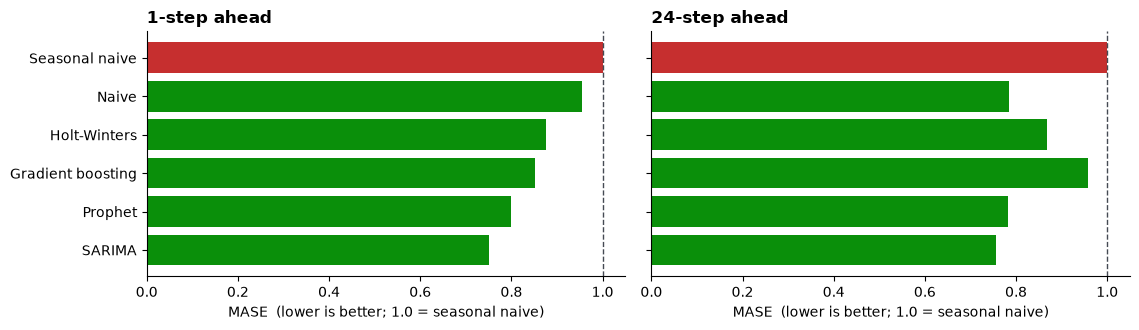

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4), sharey=True)
for ax, test in zip(axes, ["1-step ahead", "24-step ahead"]):
    d = (scores[scores.test == test].groupby("model").MASE.mean().sort_values())
    ax.barh(d.index, d.values, color=["#0a8f0a" if v < 1 else "#c62f2f" for v in d.values])
    ax.axvline(1, color="#454a53", lw=1, ls="--")
    ax.set_title(test, loc="left", fontsize=12, weight="bold")
    ax.set_xlabel("MASE  (lower is better; 1.0 = seasonal naive)")
    for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

**SARIMA(1,0,0)(1,0,0,24) wins both tests**, at MASE 0.75 on one-step-ahead and 0.76 over a full day — roughly a quarter better than "same hour yesterday" on both horizons.

Three results are worth as much as the winner:

**Prophet comes second, and that is informative.** MASE 0.80 one-step and 0.78 over a day — respectable, and better than everything except SARIMA. Prophet is built for long series with multiple overlapping seasonalities and trend changepoints. This series has 72 points, one seasonal period and no identifiable trend, so none of the machinery that makes Prophet strong has anything to work with, and it is edged out by a two-parameter autoregression. Worth knowing before reaching for it on the next short series.

**Gradient boosting loses.** With 72 observations and seven features, the flexible learner cannot beat a two-parameter linear model. That is the expected outcome at this sample size and it is why it was included — a model bake-off that only contains models you expect to win proves nothing.

**Seasonal naive is the worst model.** Its MASE is 1.0 by construction, and everything beats it. With a single weekend-to-weekday transition inside a three-day window, "same hour yesterday" is comparing Sunday to Saturday and Monday to Sunday, which is exactly where that heuristic fails.

Model selection rests on one held-out day per series and 24 one-step forecasts. That is thin, and the honest reading is that SARIMA is the defensible default here, not that it has been proven superior.

### 5.5 · The forecast

In [15]:
fc_rows = []
for (op, direction), g in series.groupby(["RadioOperatorName","TrafficDirection"]):
    g  = g.sort_values("ts")
    ly = np.log1p(g.tv_samsung.to_numpy(float))
    m  = SARIMAX(ly, order=(1,0,0), seasonal_order=(1,0,0,24),
                 trend="c", enforce_stationarity=False).fit(disp=0)
    f  = m.get_forecast(24)
    mean, ci = np.expm1(f.predicted_mean), np.expm1(f.conf_int(alpha=0.20))
    stamps = pd.date_range(g.ts.iloc[-1] + pd.Timedelta(hours=1), periods=24, freq="h")
    for i, ts in enumerate(stamps):
        fc_rows.append(dict(operator=op, direction=direction, ts=ts,
                            forecast_mb=float(mean[i]),
                            lo80_mb=float(ci[i, 0]), hi80_mb=float(ci[i, 1])))

forecast = pd.DataFrame(fc_rows)
forecast.to_csv(OUT_DIR / "q2_forecast.csv", index=False)
display((forecast.groupby(["operator","direction"])
                 .agg(next_24h_GB=("forecast_mb", lambda s: round(s.sum()/1024, 1)),
                      lo80_GB=("lo80_mb", lambda s: round(s.sum()/1024, 1)),
                      hi80_GB=("hi80_mb", lambda s: round(s.sum()/1024, 1)))))

next_24h_GB  lo80_GB  hi80_GB
operator   direction                               
Operator A Downlink         130.1     57.3    295.0
           Uplink            14.8      6.2     35.2
Operator B Downlink          99.6     35.5    279.3
           Uplink            12.8      2.6     63.7
Operator C Downlink          49.0     16.4    146.6
           Uplink             4.7      1.2     19.0

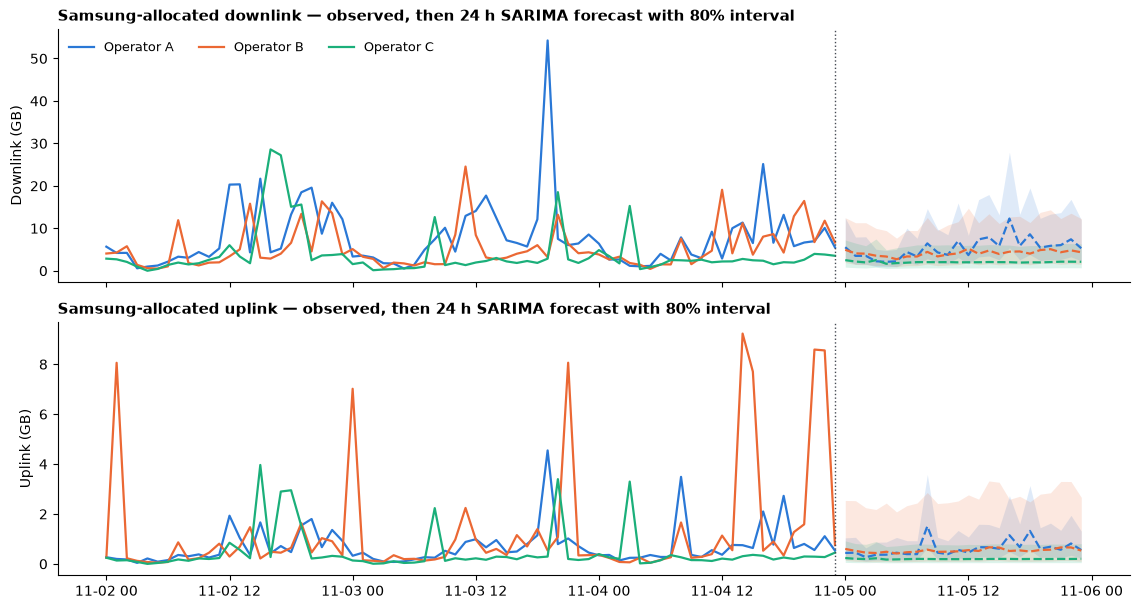

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(11.5, 6.2), sharex=True)
palette = {"Operator A":"#2a78d6", "Operator B":"#eb6834", "Operator C":"#1baf7a"}

for ax, direction in zip(axes, ["Downlink","Uplink"]):
    for op, colour in palette.items():
        h = series[(series.RadioOperatorName == op) & (series.TrafficDirection == direction)].sort_values("ts")
        f = forecast[(forecast.operator == op) & (forecast.direction == direction)].sort_values("ts")
        ax.plot(h.ts, h.tv_samsung/1024, color=colour, lw=1.6, label=op)
        ax.plot(f.ts, f.forecast_mb/1024, color=colour, lw=1.6, ls="--")
        ax.fill_between(f.ts, f.lo80_mb/1024, f.hi80_mb/1024, color=colour, alpha=.15, linewidth=0)
    ax.axvline(series.ts.max(), color="#454a53", lw=1, ls=":")
    ax.set_ylabel(f"{direction} (GB)")
    ax.set_title(f"Samsung-allocated {direction.lower()} — observed, then 24 h SARIMA forecast with 80% interval",
                 loc="left", fontsize=11, weight="bold")
    for sp in ("top","right"): ax.spines[sp].set_visible(False)
axes[0].legend(frameon=False, ncol=3, fontsize=9)
plt.tight_layout(); plt.show()

**The answer to Question 2.**

Over the next 24 hours the model expects Samsung handsets to carry **130.1 GB downlink and 14.8 GB uplink on Operator A**, **99.6 GB and 12.8 GB on Operator B**, and **49.0 GB and 4.7 GB on Operator C**.

Two comparisons stand out.

**Operator B punches far above its weight on uplink.** It carries about 77% of Operator A's downlink but roughly 87% of its uplink, and B's uplink-to-downlink ratio is materially higher than either rival's. That is a different consumption profile, not a different network size, and it is the kind of thing that shows up in a capacity plan built on downlink alone as an unexplained shortfall.

**Operator C is smaller than its coverage lead suggests.** It has the best mean RSRP of the three and carries the least Samsung traffic by a wide margin — reinforcing Section 4's conclusion from the opposite direction. Coverage leadership and traffic leadership are not the same thing in this market.

**On growth: no.** Section 5.3 showed no operator has an identifiable growth rate over this window. The forecast above is a diurnal-profile forecast for the next day, validated at MASE 0.75, and it should not be extrapolated into a weekly or monthly growth claim. Doing so would mean reporting a number whose confidence interval spans −29% to +32% per day as though it were a plan input.

## 6 · Findings

**On coverage and traffic — the counterfactual does not pay.**
Taking the coverage lead in the chosen polygon would require 4.3 dB for Operator A, 3.3 dB for Operator B, 0.5 dB for Operator C. The estimated effect on downlink is −1.0%, −0.8% and −0.1% respectively, with confidence intervals of roughly ±3 to 5 points. Zero is inside every one of them. Under the stricter specification — operators compared inside the same square kilometre in the same hour — the effect is indistinguishable from zero for both directions. The coverage-investment business case cannot be built on a traffic uplift in this data.

**The correlation that suggests otherwise is population density counted twice.**
Cells with more people generate more traffic *and* attract more capacity investment. Regressing traffic on coverage without removing that confound recovers density. Expressing traffic per device and holding cell and hour fixed removes it, and the relationship goes with it. This is the same finding the dashboard's scatter panel shows when the normalisation toggle is flipped.

**What the coverage argument should rest on instead.**
17.1% of Operator A's samples sit below −100 dBm, roughly double the exposure of the best-performing rival, and the deficit is concentrated: the worst eight cells carry 19–36 dB deficits while the median contested cell is within a few dB. That is a targeted quality and retention problem affecting a few square kilometres, and it is fixable with tilt and azimuth work before any capex. It is a strong case. It is simply not a traffic-growth case.

**On Samsung — the premise is understated and the join does not exist.**
Samsung is 89.1% of the measuring fleet, not merely the leading brand. And no device identifier links traffic to handsets, so device-level traffic here is an allocation from the RSRP device mix, not a measurement. The allocation barely binds at 89% share, but the distinction matters for anyone who might reuse the number.

**On growth — three days cannot answer it.**
Every one of the six operator × direction series returns a daily growth estimate whose confidence interval spans zero, several running from −29% to +32%. With Friday–Saturday as the Saudi weekend, the window straddles a weekend-to-weekday transition and trend is inseparable from day-of-week. A 24-hour-ahead forecast is well supported at MASE 0.75; a growth rate is not supported at all. Four to six weeks of the same feed would change that.

**On the forecast that is supported.**
SARIMA(1,0,0)(1,0,0,24) on log traffic beat naive, seasonal naive, Holt-Winters, gradient boosting and Prophet on both a one-step-ahead rolling test and a full-day-ahead test. Gradient boosting losing to a two-parameter model is the expected result at 72 observations and is reported rather than hidden. Next-day Samsung volumes: A 130.1 GB down / 14.8 GB up, B 99.6 / 12.8, C 49.0 / 4.7.

**One residual issue found while building this.**
A single 1 km cell carries 54 GB of Operator A's 85 GB at 19:00 — 65% of that hour from one bin. It sits below the 90,000 MB implausibility threshold so it survives cleaning, but any hourly peak analysis should treat 19:00 as single-cell driven rather than as a network-wide busy hour.

## 7 · Extracts for the Tableau story

In [17]:
series.to_csv(OUT_DIR / "q2_series.csv", index=False)
effects.to_csv(OUT_DIR / "q1_effects.csv", index=False)
grp.round(3).to_csv(OUT_DIR / "q1_polygon_summary.csv")
panel.to_csv(OUT_DIR / "q1_panel.csv", index=False)
pd.DataFrame([dict(lat_min=LA0, lat_max=LA1, lon_min=LO0, lon_max=LO1,
                   side_km=SIDE_KM)]).to_csv(OUT_DIR / "q1_polygon_bounds.csv", index=False)

for f in sorted(OUT_DIR.glob("*.csv")):
    print(f"{f.name:28s} {f.stat().st_size/1024:8.1f} KB")

q1_effects.csv                    0.3 KB
q1_panel.csv                    256.5 KB
q1_polygon_bounds.csv             0.1 KB
q1_polygon_summary.csv            0.2 KB
q1_scenario.csv                   0.3 KB
q2_forecast.csv                  13.4 KB
q2_model_scores.csv               7.0 KB
q2_series.csv                    35.5 KB
q2_trend.csv                      0.3 KB


| Extract | Use in the story |
|---|---|
| `q1_effects.csv` | The coefficient plot — every interval crossing zero |
| `q1_scenario.csv` | Per-operator uplift required and the predicted traffic change |
| `q1_polygon_bounds.csv` | Draw the polygon on a Tableau map |
| `q1_polygon_summary.csv` | Coverage and traffic per operator inside the polygon |
| `q1_panel.csv` | The cell-hour panel, for a scatter of RSRP against traffic per device |
| `q2_series.csv` | Observed hourly Samsung-allocated traffic |
| `q2_forecast.csv` | 24-hour forecast with 80% bands |
| `q2_model_scores.csv` | The model bake-off, for a MASE bar chart |
| `q2_trend.csv` | Growth-rate intervals — the "this is not estimable" panel |

---

### What would change the answers

**A longer window.** Four to six weeks would make growth estimable and let the seasonal model carry a weekly term as well as a daily one. It is the single highest-value addition.

**A device or session identifier in the traffic feed.** It would replace the allocation model in Section 5 with a measurement and make the Samsung question answerable directly rather than by construction.

**A coverage change actually happening.** The strongest possible answer to Question 1 is a before-and-after on a cell where tilt or power genuinely changed, with unaffected cells as controls. That is a difference-in-differences design, and it would turn an association bounded by confidence intervals into a causal estimate.